# Artificial Neural Network Practical: Customer Cart Abandonment

## Aim
Build and train a **single artificial neuron** that estimates the probability that a customer will abandon a shopping cart.

This notebook follows the worked example in the supplied lecture PDF. The model uses three customer features, a weighted sum, a sigmoid activation, a loss function, backpropagation, and gradient descent.

> **Important:** This is a small teaching example with one customer record and manually chosen starting parameters. It demonstrates the learning calculations; it is not a production-ready customer prediction system.

## What you will complete
1. Enter the customer inputs and initial parameters.
2. Perform a forward pass.
3. Convert the score into a probability using sigmoid.
4. Calculate the loss.
5. Calculate the error signal and gradients.
6. Update weights and bias using gradient descent.
7. Perform a second forward pass.
8. Train for multiple iterations and inspect the learning curve.
9. Interpret the result in business language.

## 1. Understand the example

| Symbol | Meaning | Example value |
|---|---|---:|
| `x1` | Time spent on checkout page | 2.0 |
| `x2` | Number of items in cart | 3.0 |
| `x3` | Device type (Mobile = 0) | 0.0 |
| `y` | Actual target (0 = not abandoned, 1 = abandoned) | 0.0 |
| `w1`, `w2`, `w3` | Weights | 0.5, -0.2, 0.4 |
| `b` | Bias | 0.1 |
| `alpha` | Learning rate | 0.1 |

The model architecture is:

**Customer inputs → weighted sum → sigmoid → predicted probability**

A sigmoid output is between 0 and 1. For this exercise, we use 0.5 as a simple classification threshold.

In [1]:
# 2. Import the libraries
import math
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Enter the customer information and initial parameters

We will use the exact values from the lecture example.

In [2]:
# Customer inputs
x1 = 2.0  # Time spent on checkout page
x2 = 3.0  # Number of items in cart
x3 = 0.0  # Device type: Mobile = 0

# Actual answer: 0 = cart not abandoned, 1 = cart abandoned
y = 0.0

# Initial weights
w1 = 0.5
w2 = -0.2
w3 = 0.4

# Bias and learning rate
b = 0.1
alpha = 0.1

print("CUSTOMER INFORMATION")
print("Checkout time:", x1)
print("Items in cart:", x2)
print("Device type:", x3)
print("Actual target:", y)

print("\\nINITIAL PARAMETERS")
print("w1 =", w1, " w2 =", w2, " w3 =", w3, " bias =", b)
print("Learning rate =", alpha)

CUSTOMER INFORMATION
Checkout time: 2.0
Items in cart: 3.0
Device type: 0.0
Actual target: 0.0
\nINITIAL PARAMETERS
w1 = 0.5  w2 = -0.2  w3 = 0.4  bias = 0.1
Learning rate = 0.1


## 4. Step 1 — Forward pass: calculate the weighted sum

Formula:

\[
z = w_1x_1 + w_2x_2 + w_3x_3 + b
\]

Substitute the values:

\[
z = (0.5)(2) + (-0.2)(3) + (0.4)(0) + 0.1 = 0.5
\]

The score `z` combines the evidence from the customer features.

In [3]:
z = (w1 * x1) + (w2 * x2) + (w3 * x3) + b

print("Weighted sum z =", z)

Weighted sum z = 0.4999999999999999


## 5. Step 2 — Apply the sigmoid activation function

Formula:

\[
\sigma(z) = \frac{1}{1 + e^{-z}}
\]

The sigmoid converts the weighted score into a probability between 0 and 1.

In [4]:
def sigmoid(value):
    return 1 / (1 + math.exp(-value))

y_hat = sigmoid(z)

print(f"Predicted probability = {y_hat:.4f}")
print(f"Predicted abandonment risk = {y_hat * 100:.2f}%")

prediction = 1 if y_hat >= 0.5 else 0
print("Predicted class =", prediction)

Predicted probability = 0.6225
Predicted abandonment risk = 62.25%
Predicted class = 1


## 6. Step 3 — Calculate the loss (error)

For this lecture exercise, use the half-squared-error formula:

\[
E = \frac{1}{2}(y - \hat{y})^2
\]

A smaller loss means the prediction is closer to the actual target.

In [5]:
loss = 0.5 * (y - y_hat) ** 2

print(f"Actual target = {y:.1f}")
print(f"Predicted probability = {y_hat:.4f}")
print(f"Loss = {loss:.4f}")

Actual target = 0.0
Predicted probability = 0.6225
Loss = 0.1937


## 7. Step 4 — Backpropagation: calculate the local error signal

For the sigmoid neuron and the half-squared-error loss used here:

\[
\delta = (\hat{y} - y)\hat{y}(1-\hat{y})
\]

This signal helps determine how the weights and bias should change.

In [6]:
delta = (y_hat - y) * y_hat * (1 - y_hat)

print(f"Local error signal (delta) = {delta:.4f}")

Local error signal (delta) = 0.1463


## 8. Step 5 — Calculate the gradients

The weight gradients are:

\[
\frac{\partial E}{\partial w_i} = \delta x_i
\]

The bias gradient is:

\[
\frac{\partial E}{\partial b} = \delta
\]

Each gradient indicates how changing that parameter affects the loss.

In [7]:
dw1 = delta * x1
dw2 = delta * x2
dw3 = delta * x3
db = delta

print("GRADIENTS")
print(f"dw1 = {dw1:.4f}")
print(f"dw2 = {dw2:.4f}")
print(f"dw3 = {dw3:.4f}")
print(f"db  = {db:.4f}")

GRADIENTS
dw1 = 0.2926
dw2 = 0.4388
dw3 = 0.0000
db  = 0.1463


## 9. Step 6 — Update the weights and bias with gradient descent

Update rule:

\[
w_{new} = w_{old} - \alpha \times gradient
\]

We subtract the gradient because the aim is to move toward a lower loss.

In [8]:
w1_new = w1 - alpha * dw1
w2_new = w2 - alpha * dw2
w3_new = w3 - alpha * dw3
b_new = b - alpha * db

print("UPDATED PARAMETERS")
print(f"w1 = {w1_new:.4f}")
print(f"w2 = {w2_new:.4f}")
print(f"w3 = {w3_new:.4f}")
print(f"bias = {b_new:.4f}")

UPDATED PARAMETERS
w1 = 0.4707
w2 = -0.2439
w3 = 0.4000
bias = 0.0854


## 10. Step 7 — Perform a new forward pass

Use the updated weights and bias to calculate a new score and probability.

**Numerical note about the lecture PDF:** The PDF lists updated parameters approximately as `w1 = 0.4707`, `w2 = -0.2439`, `w3 = 0.4`, and `b = 0.0854`. Substituting those values into its stated weighted-sum formula gives `z ≈ 0.2951`, and the sigmoid is approximately `0.5732`. The PDF reports `0.6062`; that reported probability does not match the listed updated parameters. This notebook calculates the result directly from the formula and parameters.

In [9]:
z_new = (w1_new * x1) + (w2_new * x2) + (w3_new * x3) + b_new
y_hat_new = sigmoid(z_new)
loss_new = 0.5 * (y - y_hat_new) ** 2

print(f"New weighted sum = {z_new:.4f}")
print(f"New predicted probability = {y_hat_new:.4f}")
print(f"New abandonment risk = {y_hat_new * 100:.2f}%")
print(f"New loss = {loss_new:.4f}")

print("\\nCOMPARISON")
print(f"Original probability: {y_hat:.4f}")
print(f"Updated probability:  {y_hat_new:.4f}")
print(f"Original loss: {loss:.4f}")
print(f"Updated loss:  {loss_new:.4f}")

New weighted sum = 0.2952
New predicted probability = 0.5733
New abandonment risk = 57.33%
New loss = 0.1643
\nCOMPARISON
Original probability: 0.6225
Updated probability:  0.5733
Original loss: 0.1937
Updated loss:  0.1643


## 11. Step 8 — Train the neuron over repeated iterations

One update is only a small learning step. Training repeats:
1. Forward pass
2. Loss calculation
3. Backpropagation
4. Gradient calculation
5. Gradient descent update

The next cell repeats these steps for the same teaching example and records the loss at each iteration.

In [10]:
# Start again from the lecture's initial parameters
w1_train, w2_train, w3_train, b_train = 0.5, -0.2, 0.4, 0.1
epochs = 100
loss_history = []
probability_history = []

for epoch in range(epochs):
    # Forward pass
    z_train = (w1_train * x1) + (w2_train * x2) + (w3_train * x3) + b_train
    y_train_hat = sigmoid(z_train)

    # Loss
    current_loss = 0.5 * (y - y_train_hat) ** 2
    loss_history.append(current_loss)
    probability_history.append(y_train_hat)

    # Backpropagation / gradients
    delta_train = (y_train_hat - y) * y_train_hat * (1 - y_train_hat)
    dw1_train = delta_train * x1
    dw2_train = delta_train * x2
    dw3_train = delta_train * x3
    db_train = delta_train

    # Gradient descent
    w1_train -= alpha * dw1_train
    w2_train -= alpha * dw2_train
    w3_train -= alpha * dw3_train
    b_train -= alpha * db_train

print("Training complete.")
print("Iterations:", epochs)
print(f"Final probability: {probability_history[-1]:.4f}")
print(f"Final loss: {loss_history[-1]:.6f}")
print("Final parameters:")
print(f"w1={w1_train:.4f}, w2={w2_train:.4f}, w3={w3_train:.4f}, bias={b_train:.4f}")

Training complete.
Iterations: 100
Final probability: 0.0688
Final loss: 0.002367
Final parameters:
w1=0.0555, w2=-0.8667, w3=0.4000, bias=-0.1222


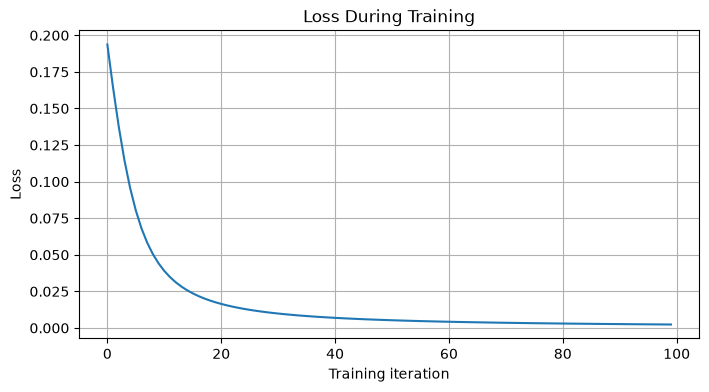

In [11]:
# Plot how the loss changes during training
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Loss During Training")
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

## 12. Business interpretation

- **Inputs** represent observed customer behaviour.
- **Weights** represent how strongly each input contributes to the model's score.
- **Weighted sum** combines the evidence.
- **Sigmoid** converts the score into an abandonment probability.
- **Loss** measures the difference between the prediction and the known target.
- **Backpropagation** calculates how the parameters contributed to the error.
- **Gradient descent** adjusts the parameters to reduce the loss.

In a real business setting, a well-tested model could help identify customers who may need assistance during checkout. For example, a business might investigate whether clearer delivery information or a simpler checkout process helps reduce cart abandonment.

**Important limitation:** This notebook uses only one example record and a manually chosen starting point. A real prediction system needs a representative dataset, separate training and testing data, appropriate feature preparation, and evaluation on unseen records.

## 13. Practical questions — answer in your own words

1. What is the purpose of the weights?
2. Why do we add a bias?
3. What does the sigmoid function do?
4. What does a predicted probability of `0.6225` mean?
5. Why do we calculate loss?
6. What is the role of backpropagation?
7. Why does gradient descent subtract the gradient?
8. What does the learning rate control?
9. Why is one training iteration usually not enough?
10. Why should we not treat this one-record demonstration as a production-ready model?

## 14. Completion checklist

- [ ] I ran all cells from top to bottom.
- [ ] I can identify the inputs, weights, bias, and target.
- [ ] I calculated the weighted sum.
- [ ] I applied sigmoid to get a probability.
- [ ] I calculated the loss.
- [ ] I calculated the error signal and gradients.
- [ ] I updated the weights and bias.
- [ ] I ran the repeated training loop and viewed the loss plot.
- [ ] I can explain the business meaning of the output.